## Creazione tabella finale con indicatori per clustering e classification

In [3]:
# Import libraries
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from pyexpat import features
from scipy.stats import pearsonr
import matplotlib.colors as mcolors

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


In [87]:
# Loading Datasets
patients_df = pd.read_csv('../datasets/patients_cleaned.csv')
triage_df = pd.read_csv('../datasets/triage_cleaned.csv')
vital_sign_df = pd.read_csv('../datasets/vital_sign_cleaned.csv')

In [3]:
print("triage_df: ", triage_df.columns)
print("-"*70)
print("vital_sign_df: ", vital_sign_df.columns)
print("-"*70)
print('patients_df: ', patients_df.columns)

triage_df:  Index(['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate',
       'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint'],
      dtype='object')
----------------------------------------------------------------------
vital_sign_df:  Index(['subject_id', 'stay_id', 'charttime', 'temperature', 'heartrate',
       'resprate', 'o2sat', 'sbp', 'dbp', 'pain'],
      dtype='object')
----------------------------------------------------------------------
patients_df:  Index(['study_id', 'subject_id', 'ed_stay_id', 'diagnosis', 'gender', 'age',
       'dod', 'age_range', 'diagnosis_categories', 'num_categories'],
      dtype='object')


---
### Merge triage e vital sign in unica tabella

In [88]:
vital_sign_df = vital_sign_df.drop(columns=["charttime", "pain", "stay_id"])
triage_df = triage_df.drop(columns=['pain', 'acuity', 'chiefcomplaint', "stay_id"])
patients_df = patients_df.drop(columns=['ed_stay_id'])


In [5]:
print(patients_df.shape, triage_df.shape, vital_sign_df.shape)

(41415, 9) (89138, 7) (251123, 7)


In [17]:
print("triage_df: ", triage_df.columns)
print("-"*70)
print("vital_sign_df: ", vital_sign_df.columns)
print("-"*70)
print('patients_df: ', patients_df.columns)

triage_df:  Index(['subject_id', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp',
       'dbp'],
      dtype='object')
----------------------------------------------------------------------
vital_sign_df:  Index(['subject_id', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp',
       'dbp'],
      dtype='object')
----------------------------------------------------------------------
patients_df:  Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories'],
      dtype='object')


---
### Merge triage e vital_sign

In [89]:
merge_tr_vt_df = pd.concat([triage_df, vital_sign_df], axis=0)

In [90]:
# Controlla duplicati su specifiche colonne
duplicates = merge_tr_vt_df[merge_tr_vt_df.duplicated(subset=merge_tr_vt_df.columns, keep=False)]

# Visualizza i duplicati
duplicates


,subject_id,temperature,heartrate,resprate,o2sat,sbp,dbp
5,10000117,97.1,119.0,16.0,99.0,100.0,55.0
6,10000117,97.6,81.0,16.0,100.0,148.0,83.0
7,10000117,97.5,104.0,16.0,99.0,130.0,71.0
9,10000980,94.8,57.0,18.0,98.0,151.0,84.0
14,10000980,97.3,71.0,16.0,99.0,153.0,83.0
...,...,...,...,...,...,...,...
251097,19998350,97.2,87.0,19.0,100.0,152.0,81.0
251100,19998350,97.8,89.0,20.0,98.0,153.0,80.0
251112,19999784,98.8,92.0,18.0,100.0,122.0,77.0
251114,19999784,98.6,80.0,18.0,100.0,161.0,100.0


In [91]:
# Mantieni la prima occorrenza e rimuovi le successive
merge_tr_vt_df = merge_tr_vt_df.drop_duplicates(keep='first')

In [92]:
merge_tr_vt_df

,subject_id,temperature,heartrate,resprate,o2sat,sbp,dbp
0,10000032,97.8,87.0,14.0,97.0,71.0,43.0
1,10000032,98.4,70.0,16.0,97.0,106.0,63.0
2,10000032,99.4,105.0,18.0,96.0,106.0,57.0
3,10000032,98.9,88.0,18.0,97.0,116.0,88.0
4,10000032,98.7,77.0,16.0,98.0,96.0,50.0
...,...,...,...,...,...,...,...
251117,19999784,97.9,83.0,18.0,98.0,142.0,78.0
251118,19999784,98.6,75.0,16.0,99.0,123.0,82.0
251120,19999784,97.9,82.0,18.0,99.0,141.0,76.0
251121,19999784,98.1,68.0,16.0,100.0,139.0,88.0


In [22]:
merge_tr_vt_df.isnull().sum()

subject_id     0
temperature    0
heartrate      0
resprate       0
o2sat          0
sbp            0
dbp            0
dtype: int64

In [23]:
# salva tabella del merge
merge_tr_vt_df.to_csv('../datasets/merge_triage_vital_sign.csv', index=False)

### Integrazione degli indicatori, creati a partire da `merge_tr_vt_df`, alla tabella di base patients

In [152]:
merge_tr_vt_df = pd.read_csv('../datasets/merge_triage_vital_sign.csv')
patients_df = pd.read_csv('../datasets/patients_cleaned.csv')
patients_df = patients_df.drop(columns=['ed_stay_id'])
icd10_category = pd.read_csv('../datasets/icd10_category.csv')

In [153]:
# https://www.ioss.it/guida-ai-parametri-vitali/

# Calcolo delle feature singole per ogni riga
# Mean Arterial Pressure (MAP)
merge_tr_vt_df['mean_arterial_pressure'] = (merge_tr_vt_df['sbp'] + 2 * merge_tr_vt_df['dbp']) / 3

# RR/HR ratio (quante respirazioni avvengono per ogni battito cardiaco)
merge_tr_vt_df['RR_HR_ratio'] = merge_tr_vt_df['resprate'] / merge_tr_vt_df['heartrate']

# Calcolo del MIN e MAX per ogni paziente (subject_id)
feature_creation = merge_tr_vt_df.groupby('subject_id').agg(
    temperature_min=('temperature', 'min'),
    temperature_max=('temperature', 'max'),
    temperature_mean=('temperature', 'mean'),
    o2sat_min=('o2sat', 'min'),
    o2sat_mean=('o2sat', 'mean'),
    mean_arterial_pressure_min=('mean_arterial_pressure', 'min'),
    mean_arterial_pressure_max=('mean_arterial_pressure', 'max'),
    mean_arterial_pressure_mean=('mean_arterial_pressure', 'mean'),
    RR_HR_ratio_min=('RR_HR_ratio', 'min'),
    RR_HR_ratio_max=('RR_HR_ratio', 'max'),
    RR_HR_ratio_mean=('RR_HR_ratio', 'mean')
).reset_index()
#,
# heartrate_mean=('heartrate', 'mean'),
# resprate_mean=('resprate', 'mean'),
# sbp_mean=('sbp', 'mean'),
# dbp_mean=('dbp', 'mean')
# Aggiungi la colonna temperature_mean al DataFrame originale
patients_df = patients_df.merge(feature_creation, on='subject_id', how='inner')
patients_df

,study_id,subject_id,diagnosis,gender,age,dod,age_range,diagnosis_categories,num_categories,temperature_min,temperature_max,temperature_mean,o2sat_min,o2sat_mean,mean_arterial_pressure_min,mean_arterial_pressure_max,mean_arterial_pressure_mean,RR_HR_ratio_min,RR_HR_ratio_max,RR_HR_ratio_mean
0,40689238,10000032,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",1,52.0,1,40-60,"['A00-B99', 'I00-I99', 'K00-K95', 'V00-Y99', '...",9,97.7,99.4,98.366667,93.0,96.583333,52.333333,97.333333,71.055556,0.160920,0.236842,0.197211
1,48446569,10000117,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",1,57.0,0,40-60,"['M00-M99', 'I00-I99', 'K00-K95', 'G00-G99', '...",9,97.1,98.7,97.977778,95.0,98.444444,70.000000,104.666667,91.925926,0.134454,0.263158,0.199179
2,47218930,10000764,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",0,86.0,0,80-100,"['I00-I99', 'N00-N99', 'V00-Y99', 'Z00-Z99', '...",8,97.6,98.9,98.200000,94.0,96.500000,85.000000,98.000000,92.750000,0.134615,0.260870,0.196104
3,42546971,10000980,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",1,75.0,1,60-80,"['I00-I99', 'N00-N99', 'Z00-Z99', 'J00-J99', '...",5,94.8,98.9,97.610000,97.0,99.366667,86.333333,121.666667,103.877778,0.197183,0.394366,0.265995
4,40925049,10001176,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",1,64.0,0,60-80,"['I00-I99', 'K00-K95', 'G00-G99', 'D50-D89', '...",8,98.0,101.3,99.600000,93.0,95.750000,77.666667,94.666667,87.583333,0.178218,0.202020,0.187370
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39472,41514157,19998350,"['J45998', 'G4733', 'E119', 'R0789', 'F419', '...",0,53.0,0,40-60,"['I00-I99', 'G00-G99', 'Z00-Z99', 'J00-J99', '...",7,97.2,99.2,98.172000,94.0,97.760000,71.666667,118.666667,96.026667,0.174757,0.317460,0.236859
39473,43267699,19998444,"['Z9049', 'F39', 'K219', 'F1021', 'R3911', 'K8...",0,38.0,0,20-40,"['K00-K95', 'G00-G99', 'Z00-Z99', 'F01-F99', '...",5,96.8,98.8,97.936364,95.0,97.636364,77.666667,111.333333,96.939394,0.153846,0.285714,0.216469
39474,40314343,19999156,"['R079', 'F419']",1,62.0,0,60-80,"['F01-F99', 'R00-R99']",2,97.0,98.1,97.550000,97.0,98.000000,83.666667,104.333333,94.000000,0.195652,0.200000,0.197826
39475,42489677,19999733,"['T7840XA', 'Y92099']",1,19.0,0,0-20,"['V00-Y99', 'S00-T88']",2,98.0,98.1,98.050000,100.0,100.000000,69.666667,87.333333,78.500000,0.296296,0.300000,0.298148


In [154]:
# patients_df['temperature_status'] = pd.cut(
#     patients_df['temperature_mean'],
#     bins=[0, 97.7, 99.5, 105.8],
#     labels=[1, 2, 3]  # 1: ipotermia | 2: normale | 3: febbre
# )
patients_df['temperature_class_mean'] = pd.cut(
    patients_df['temperature_mean'],
    bins=[0, 97.7, 99.5, 105.8],
    labels=['ipotermia', 'normale', 'febbre']  # 1: ipotermia | 2: normale | 3: febbre
)
patients_df['temperature_class_min'] = pd.cut(
    patients_df['temperature_min'],
    bins=[0, 97.7, 99.5, 105.8],
    labels=['ipotermia', 'normale', 'febbre']  # 1: ipotermia | 2: normale | 3: febbre
)
patients_df['temperature_class_max'] = pd.cut(
    patients_df['temperature_max'],
    bins=[0, 97.7, 99.5, 105.8],
    labels=['ipotermia', 'normale', 'febbre']  # 1: ipotermia | 2: normale | 3: febbre
)

# patients_df['o2sat_status'] = pd.cut(
#     patients_df['o2sat_mean'],
#     bins=[0, 90, 95, 100],
#     labels=[1, 2, 3]  # critico | basso | normale
# )
patients_df['o2sat_class_mean'] = pd.cut(
    patients_df['o2sat_mean'],
    bins=[0, 90, 95, 100],
    labels=['critico', 'basso', 'normale']  # critico | basso | normale
)
patients_df['o2sat_class_min'] = pd.cut(
    patients_df['o2sat_min'],
    bins=[0, 90, 95, 100],
    labels=['critico', 'basso', 'normale']  # critico | basso | normale
)

# Calcolo della pressione arteriosa media (MAP) https://www.healthline.com/health/mean-arterial-pressure#how-to-calculate
# patients_df['mean_arterial_pressure'] = (patients_df['sbp_mean'] + 2 * patients_df['dbp_mean']) / 3

# patients_df['mean_arterial_pressure_status'] = pd.cut(
#     patients_df['mean_arterial_pressure'],
#     bins=[0, 70, 100, float('inf')],
#     labels=[1, 2, 3]  # ipotensione | normale | ipertensione
# )
patients_df['mean_arterial_pressure_class_mean'] = pd.cut(
    patients_df['mean_arterial_pressure_mean'],
    bins=[0, 70, 100, float('inf')],
    labels=['ipotensione', 'normale', 'ipertensione']  # ipotensione | normale | ipertensione
)
patients_df['mean_arterial_pressure_class_min'] = pd.cut(
    patients_df['mean_arterial_pressure_min'],
    bins=[0, 70, 100, float('inf')],
    labels=['ipotensione', 'normale', 'ipertensione']  # ipotensione | normale | ipertensione
)
patients_df['mean_arterial_pressure_class_max'] = pd.cut(
    patients_df['mean_arterial_pressure_max'],
    bins=[0, 70, 100, float('inf')],
    labels=['ipotensione', 'normale', 'ipertensione']  # ipotensione | normale | ipertensione
)

# # RR/HR ratio (quante respirazioni avvengono per ogni battito cardiaco)
# patients_df['RR_HR_ratio'] = patients_df['resprate_mean'] / patients_df['heartrate_mean']
# # range trovato manualmente
# patients_df['RR_HR_ratio_status'] = pd.cut(
#     patients_df['RR_HR_ratio'],
#     bins=[0, 0.12, 0.3, float('inf')],
#     labels=[1, 2, 3] # 'Basso', 'Normale', 'Alto'
# )
patients_df['RR_HR_ratio_class_mean'] = pd.cut(
    patients_df['RR_HR_ratio_mean'],
    bins=[0, 0.12, 0.3, float('inf')],
    labels=['Basso', 'Normale', 'Alto'] # 'Basso', 'Normale', 'Alto'
)
patients_df['RR_HR_ratio_class_min'] = pd.cut(
    patients_df['RR_HR_ratio_min'],
    bins=[0, 0.12, 0.3, float('inf')],
    labels=['Basso', 'Normale', 'Alto'] # 'Basso', 'Normale', 'Alto'
)

patients_df['RR_HR_ratio_class_max'] = pd.cut(
    patients_df['RR_HR_ratio_max'],
    bins=[0, 0.12, 0.3, float('inf')],
    labels=['Basso', 'Normale', 'Alto'] # 'Basso', 'Normale', 'Alto'
)
# patients_df['age_range_status'] = pd.cut(
#     patients_df['age'],
#     bins=[0, 30, 40, 50, 60, 70, 80, 90, 110],
#     labels=[1, 2, 3, 4, 5, 6, 7, 8] # 'Basso', 'Normale', 'Alto'
# )

patients_df['age_range_class'] = pd.cut(
    patients_df['age'],
    bins=[0, 30, 40, 50, 60, 70, 80, 90, float('inf')],
    labels=['0-30', '30-40', '40-50', '50-60', '60-70', '70-80', '80-90', '90-110'] # 'Basso', 'Normale', 'Alto'
)
# Eliminazione attributi non piu utili, perche fanno parte di indicatori composti
# patients_df = patients_df.drop(columns=['heartrate_mean', 'resprate_mean', 'sbp_mean', 'dbp_mean'], errors='ignore')

In [38]:
# Salva il risultato in un file CSV
# patients_df.to_csv("../datasets/patients_min_max_additional_features.csv", index=False)

In [155]:
patients_df.to_csv('../datasets/general_patients_TAB.csv', index=False)

---
## **Analisi Distribuzione**

In [4]:
patients_df = pd.read_csv('../datasets/general_patients_TAB.csv')
icd10_category = pd.read_csv('../datasets/icd10_category.csv')

In [29]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'o2sat_min', 'o2sat_max',
       'mean_arterial_pressure_min', 'mean_arterial_pressure_max',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'temperature_mean', 'o2sat_mean',
       'heartrate_mean', 'resprate_mean', 'sbp_mean', 'dbp_mean',
       'temperature_status', 'temperature_class', 'o2sat_status',
       'o2sat_class', 'mean_arterial_pressure',
       'mean_arterial_pressure_status', 'mean_arterial_pressure_class',
       'RR_HR_ratio', 'RR_HR_ratio_status', 'RR_HR_ratio_class',
       'age_range_status', 'age_range_class'],
      dtype='object')

In [207]:
def istogram_view(attr_split, attr_split_value1, attr_split_value2, name1, name2, title):
    attributes = [
        'temperature_class_min', 'temperature_class_mean', 'temperature_class_max',
        'o2sat_class_mean', 'o2sat_class_min', 'age_range_class',
        'mean_arterial_pressure_class_min', 'mean_arterial_pressure_class_mean',
        'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_min',
        'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_max'
    ]
    n_cols = 3
    n_rows = -(-len(attributes) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, attr in enumerate(attributes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]

        # Seleziona i dati per maschi e femmine
        male_data = patients_df[patients_df[attr_split] == attr_split_value1]
        female_data = patients_df[patients_df[attr_split] == attr_split_value2]

        # Conta i valori per l'attributo e calcola il tasso di decesso
        male_counts = male_data[attr].value_counts()
        female_counts = female_data[attr].value_counts()

        male_dod_percent = (male_data.groupby(attr, observed=True)['dod'].mean() * 100).reindex(male_counts.index).fillna(0)
        female_dod_percent = (female_data.groupby(attr, observed=True)['dod'].mean() * 100).reindex(female_counts.index).fillna(0)

        # Crea il DataFrame per il grafico
        dist_df = pd.DataFrame({
            name1: male_counts,
            name2: female_counts
        }).fillna(0)

        # Crea il grafico
        dist_df.plot(kind='bar', ax=ax, alpha=0.7)

        # # Aggiungi percentuali sulle barre
        # for i, (bar, percent) in enumerate(zip(ax.patches, male_dod_percent.tolist() + female_dod_percent.tolist())):
        #     if percent > 0:
        #         ax.text(
        #             bar.get_x() + bar.get_width() / 2,
        #             bar.get_height() + 1,
        #             f'{percent:.1f}',
        #             ha='center',
        #             fontsize=14
        #         )

        # Configura il grafico
        ax.set_title(f'Distribuzione di {attr}', fontsize=12)
        ax.set_xlabel(attr, fontsize=10)
        ax.set_ylabel('Conteggio', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend(title=title)

    # Rimuove i subplot vuoti
    for i in range(len(attributes), n_rows * n_cols):
        fig.delaxes(axes.flat[i])
    plt.tight_layout()
    plt.show()


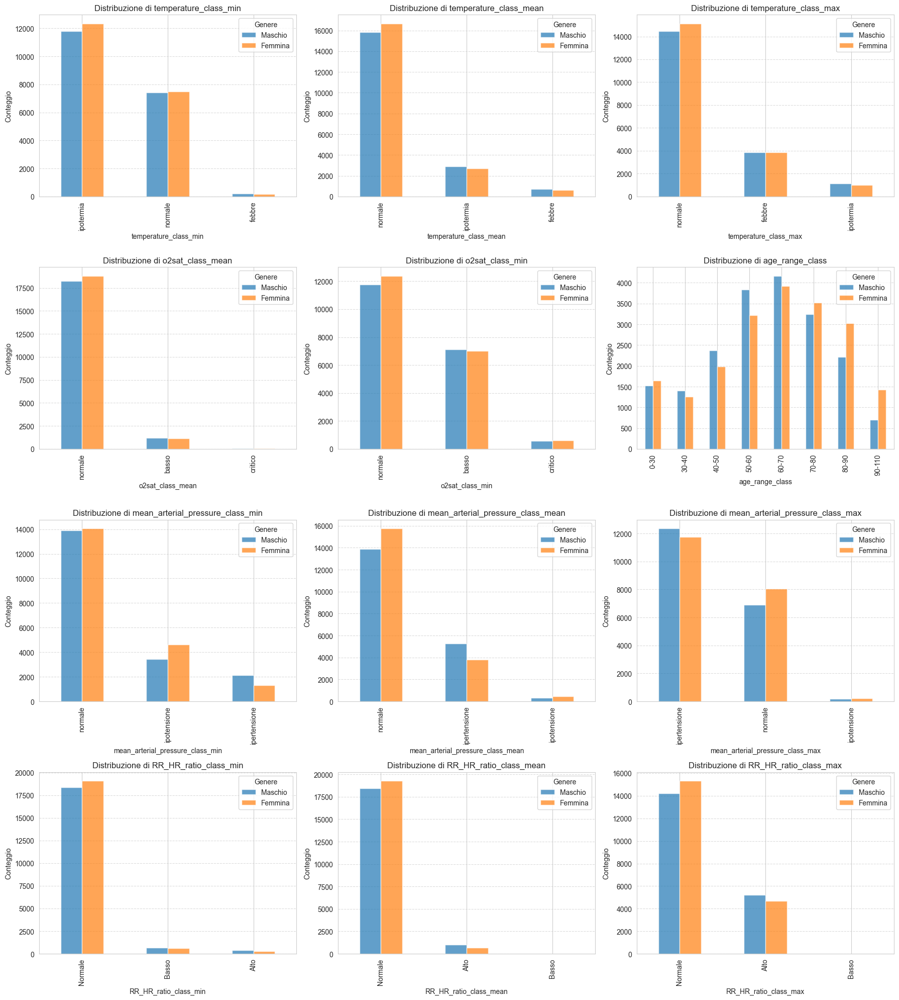

In [208]:
istogram_view('gender', 0, 1, 'Maschio', 'Femmina', 'Genere')

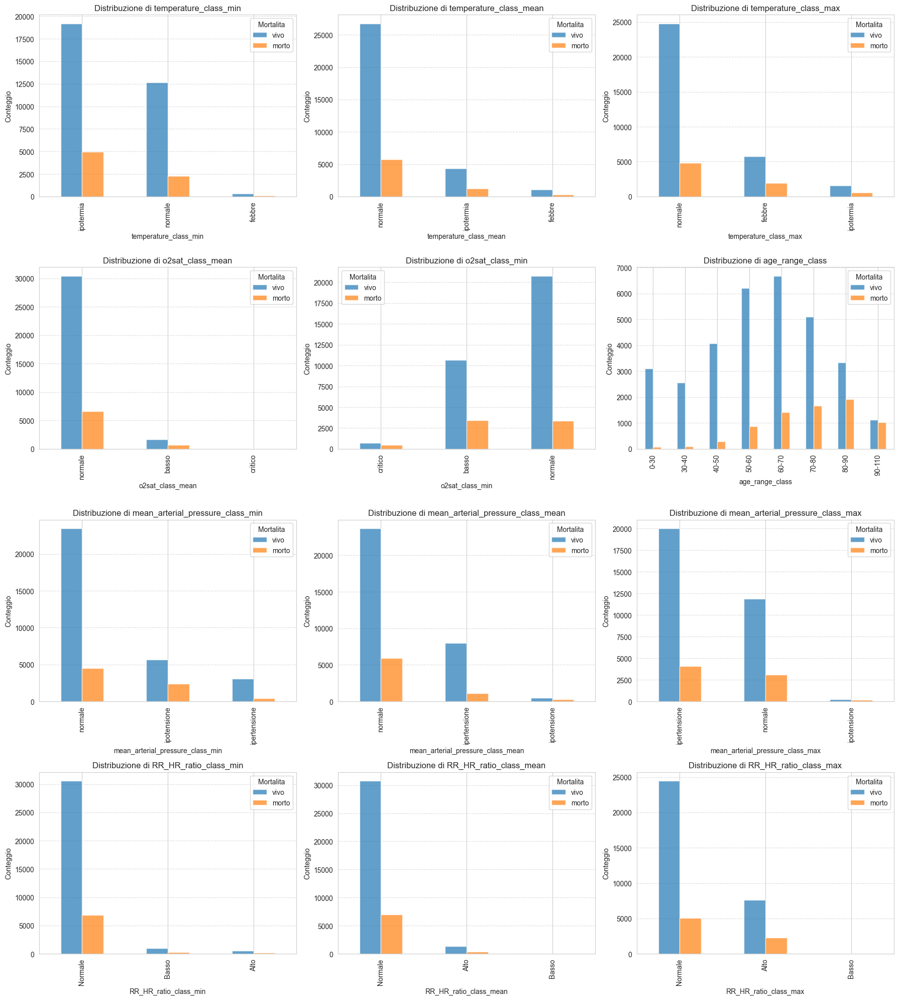

In [209]:
istogram_view('dod', 0, 1, 'vivo', 'morto', 'Mortalita')

In [6]:
def num_categories(map_colors, attr, title):
        # Raggruppa i dati per range di età e calcola la distribuzione
        map_groups = patients_df.groupby(attr)
        
        plt.figure(figsize=(14, 6))
        bar_width = 0.22  # Larghezza di ogni barra
        space_between_categories = 0.5  # Spazio tra diversi numeri di categorie
        max_categories = patients_df['num_categories'].max()
        base_positions = np.arange(max_categories + 1) * (bar_width * len(map_groups) + space_between_categories)
        
        # Aggiungi barre per ciascun range di età
        for i, (map, group) in enumerate(map_groups):
            category_counts = group['num_categories'].value_counts().sort_index()
            positions = base_positions + i * bar_width
            color = map_colors.get(map, 'gray')
            plt.bar(positions[:len(category_counts)], category_counts.values, width=bar_width,
                    label=f"{map}", color=color, edgecolor='black')
        
        plt.title(f"Distribuzione del Numero di Categorie Diagnostiche per {title}", fontsize=16)
        plt.xlabel("Numero di Categorie per paziente", fontsize=14)
        plt.ylabel("Frequenza", fontsize=14)
        plt.xticks(base_positions, range(max_categories + 1), fontsize=12)
        plt.legend(fontsize=12)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend(fontsize=12, title=title)
        plt.tight_layout()
        plt.show()


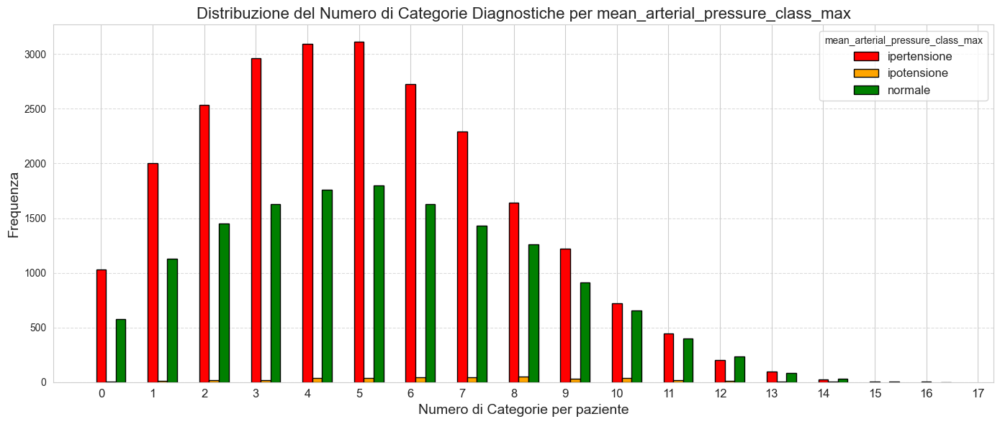

--------------------------
Classe: ipertensione
num_categories
6     3113
5     3094
4     2963
7     2726
3     2533
8     2295
2     2002
9     1640
10    1220
1     1030
11     719
12     443
13     203
14      97
15      27
16       7
17       2
Name: count, dtype: int64
--------------------------
Classe: ipotensione
num_categories
9     51
8     46
7     46
11    40
6     39
5     35
10    33
4     21
12    20
3     16
13    14
2      9
1      4
15     3
14     3
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
6     1800
5     1760
7     1627
4     1626
3     1450
8     1434
9     1257
2     1130
10     912
11     658
1      577
12     399
13     234
14      83
15      30
16       5
17       1
Name: count, dtype: int64


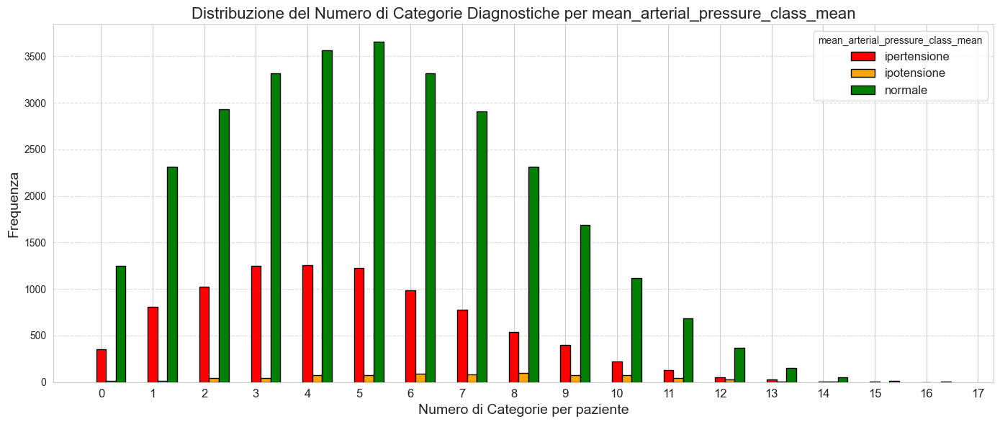

--------------------------
Classe: ipertensione
num_categories
5     1254
4     1249
6     1222
3     1023
7      987
2      809
8      781
9      537
10     399
1      351
11     225
12     130
13      55
14      30
15       4
16       2
17       1
Name: count, dtype: int64
--------------------------
Classe: ipotensione
num_categories
9     97
7     91
8     85
11    76
10    75
6     74
5     73
12    48
3     41
4     41
13    30
2     16
1     11
15     5
14     4
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
6     3656
5     3562
7     3321
4     3320
3     2935
8     2909
2     2316
9     2314
10    1691
1     1249
11    1116
12     684
13     366
14     149
15      51
16      10
17       2
Name: count, dtype: int64


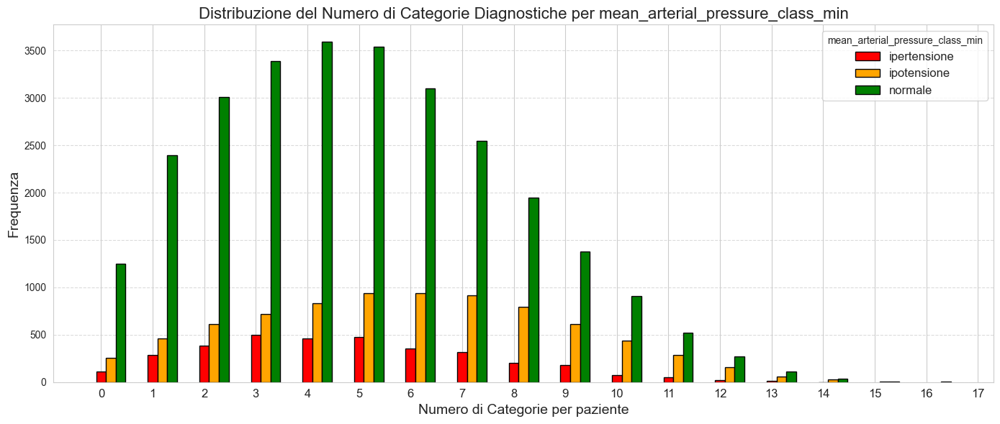

--------------------------
Classe: ipertensione
num_categories
4     498
6     472
5     463
3     382
7     357
8     319
2     284
9     202
10    178
1     110
11     75
12     51
13     23
14     15
16      1
Name: count, dtype: int64
--------------------------
Classe: ipotensione
num_categories
7     941
6     937
8     913
5     834
9     797
4     721
3     611
10    610
2     463
11    434
12    289
1     255
13    158
14     55
15     27
16      6
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
5     3592
6     3543
4     3391
7     3101
3     3006
8     2543
2     2394
9     1949
10    1377
1     1246
11     908
12     522
13     270
14     113
15      33
16       5
17       3
Name: count, dtype: int64


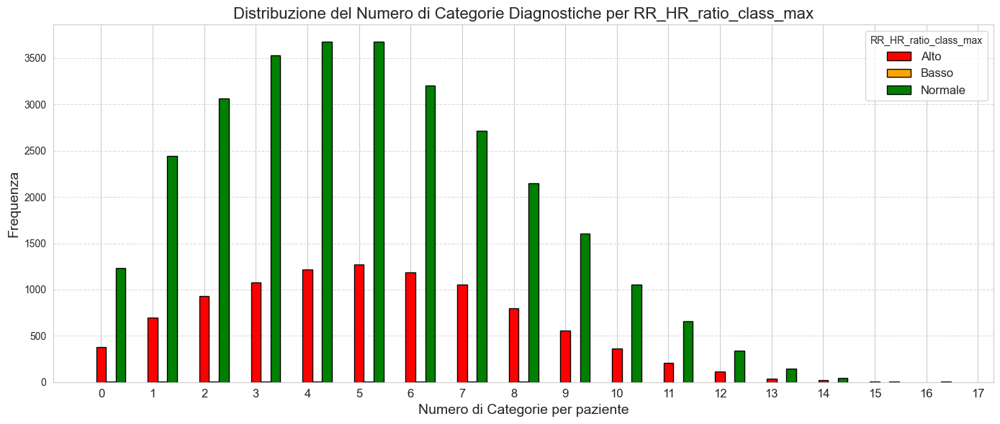

--------------------------
Classe: Alto
num_categories
6     1271
5     1213
7     1187
4     1075
8     1054
3      928
9      798
2      697
10     556
1      380
11     361
12     207
13     111
14      39
15      18
16       4
Name: count, dtype: int64
--------------------------
Classe: Basso
num_categories
3     6
6     4
7     4
2     4
10    4
4     2
14    2
5     2
8     2
Name: count, dtype: int64
--------------------------
Classe: Normale
num_categories
6     3677
5     3674
4     3533
7     3208
3     3065
8     2719
2     2440
9     2150
10    1605
1     1231
11    1056
12     655
13     340
14     142
15      42
16       8
17       3
Name: count, dtype: int64


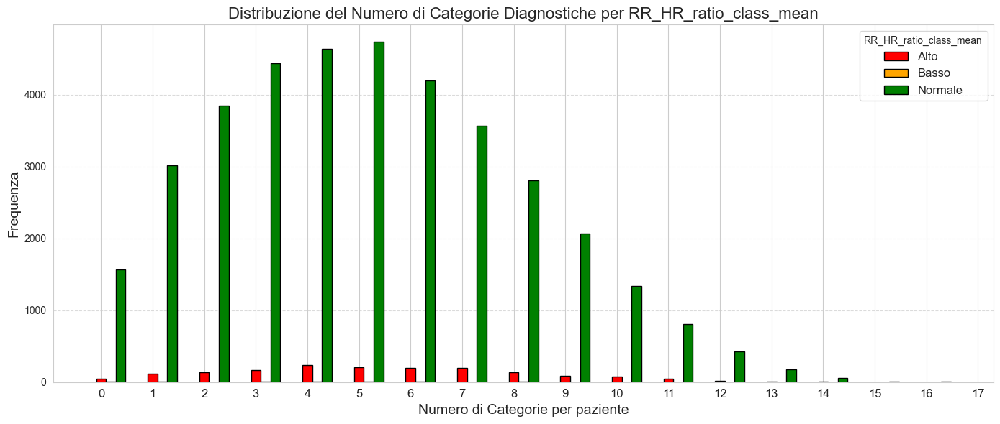

--------------------------
Classe: Alto
num_categories
5     242
6     207
8     202
7     199
4     167
3     142
9     139
2     114
10     87
11     76
12     49
1      47
13     21
14      5
15      3
Name: count, dtype: int64
--------------------------
Classe: Basso
num_categories
6     7
2     7
7     6
3     6
5     5
10    5
8     3
4     2
14    2
9     2
13    1
11    1
12    1
Name: count, dtype: int64
--------------------------
Classe: Normale
num_categories
6     4738
5     4642
4     4441
7     4194
3     3851
8     3570
2     3020
9     2807
10    2073
1     1564
11    1340
12     812
13     429
14     176
15      57
16      12
17       3
Name: count, dtype: int64


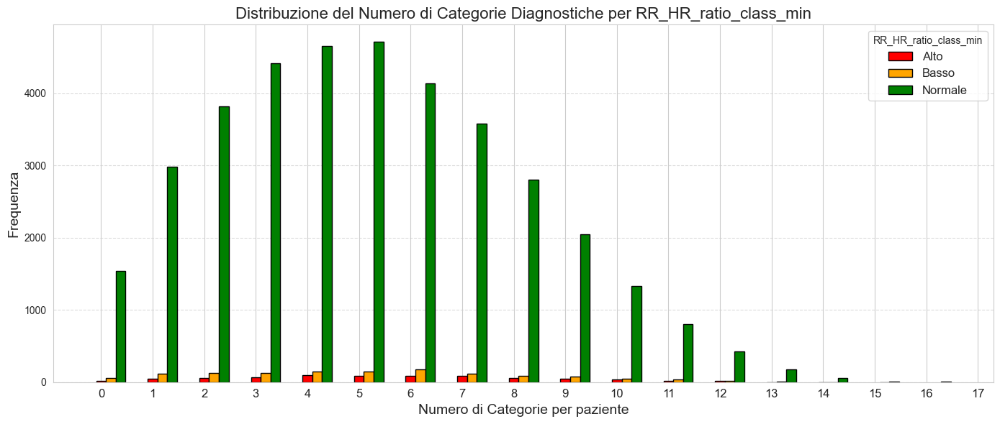

--------------------------
Classe: Alto
num_categories
5     94
6     89
7     83
8     83
4     65
9     58
3     54
2     46
10    44
11    39
12    19
1     16
13    13
14     1
15     1
Name: count, dtype: int64
--------------------------
Classe: Basso
num_categories
7     176
6     150
5     143
3     126
4     126
8     116
2     114
9      88
10     72
1      58
11     51
12     35
13     13
14      8
16      2
15      1
Name: count, dtype: int64
--------------------------
Classe: Normale
num_categories
6     4713
5     4652
4     4419
7     4140
3     3819
8     3576
2     2981
9     2802
10    2049
1     1537
11    1327
12     808
13     425
14     174
15      58
16      10
17       3
Name: count, dtype: int64


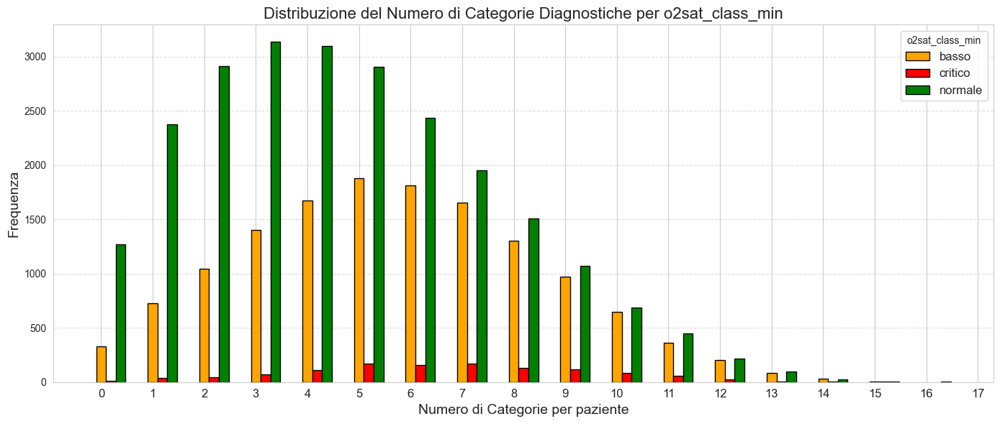

--------------------------
Classe: basso
num_categories
6     1879
7     1810
5     1677
8     1655
4     1401
9     1306
3     1042
10     975
2      726
11     646
12     361
1      330
13     205
14      82
15      28
16       6
Name: count, dtype: int64
--------------------------
Classe: critico
num_categories
6     169
8     168
7     155
9     133
10    116
5     113
11     87
4      72
12     55
3      44
2      40
13     27
1      13
14      6
15      5
16      2
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
4     3137
5     3099
3     2913
6     2904
7     2434
2     2375
8     1952
9     1509
1     1268
10    1074
11     684
12     446
13     219
14      95
15      27
16       4
17       3
Name: count, dtype: int64


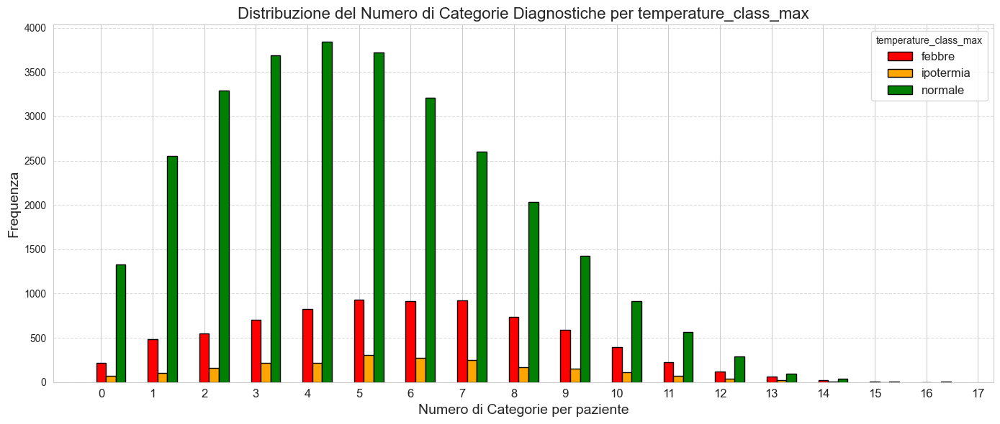

--------------------------
Classe: febbre
num_categories
6     927
8     926
7     913
5     828
9     739
4     702
10    587
3     549
2     481
11    396
12    224
1     216
13    121
14     66
15     21
16      6
17      1
Name: count, dtype: int64
--------------------------
Classe: ipotermia
num_categories
6     305
7     276
8     247
4     220
5     218
9     171
3     156
10    155
11    108
2     106
12     72
1      67
13     38
14     21
15      2
16      1
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
5     3843
6     3720
4     3688
3     3294
7     3210
8     2602
2     2554
9     2038
10    1423
1     1328
11     913
12     566
13     292
14      96
15      37
16       5
17       2
Name: count, dtype: int64


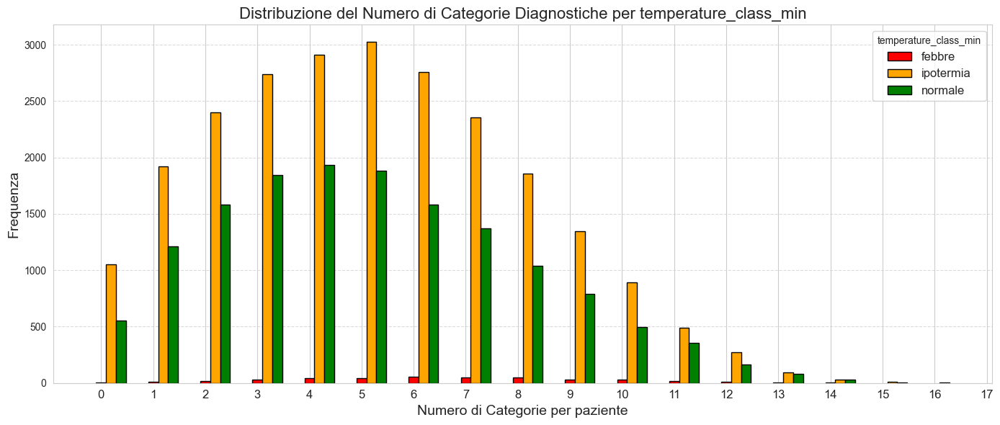

--------------------------
Classe: febbre
num_categories
7     58
8     51
9     51
6     46
5     45
10    33
11    31
4     29
3     19
12    15
13    13
2     11
14     7
1      5
15     2
Name: count, dtype: int64
--------------------------
Classe: ipotermia
num_categories
6     3025
5     2909
7     2760
4     2737
3     2398
8     2353
2     1918
9     1858
10    1344
1     1051
11     891
12     493
13     274
14      97
15      29
16       9
17       3
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
5     1935
6     1881
4     1844
3     1582
7     1581
8     1371
2     1212
9     1039
10     788
1      555
11     495
12     354
13     164
14      79
15      29
16       3
Name: count, dtype: int64


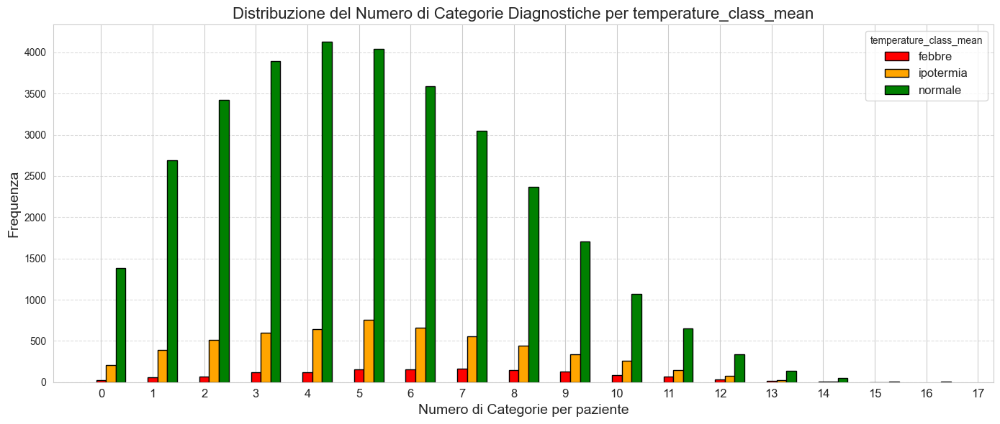

--------------------------
Classe: febbre
num_categories
8     166
7     155
6     152
9     145
10    126
5     118
4     116
11     85
3      69
12     68
2      57
13     34
1      20
14     17
15      6
16      1
Name: count, dtype: int64
--------------------------
Classe: ipotermia
num_categories
6     753
7     658
5     642
4     597
8     558
3     508
9     438
2     394
10    336
11    258
1     211
12    146
13     76
14     28
15      5
16      1
Name: count, dtype: int64
--------------------------
Classe: normale
num_categories
5     4129
6     4047
4     3897
7     3586
3     3422
8     3051
2     2690
9     2365
10    1703
1     1380
11    1074
12     648
13     341
14     138
15      49
16      10
17       3
Name: count, dtype: int64


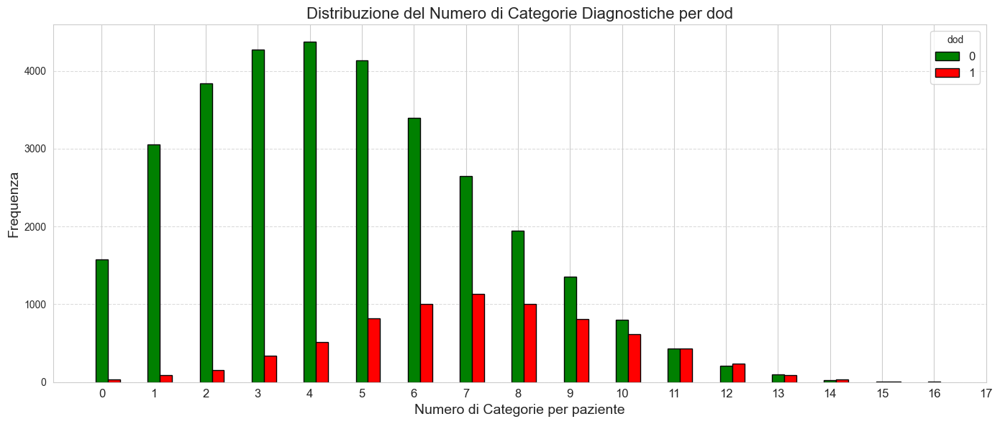

--------------------------
Classe: 0
num_categories
5     4373
4     4274
6     4132
3     3841
7     3394
2     3053
8     2646
9     1943
1     1573
10    1351
11     798
12     433
13     211
14      95
15      23
16       6
17       3
Name: count, dtype: int64
--------------------------
Classe: 1
num_categories
8     1129
9     1005
7     1005
6      820
10     814
11     619
5      516
12     429
4      336
13     240
3      158
14      88
2       88
1       38
15      37
16       6
Name: count, dtype: int64


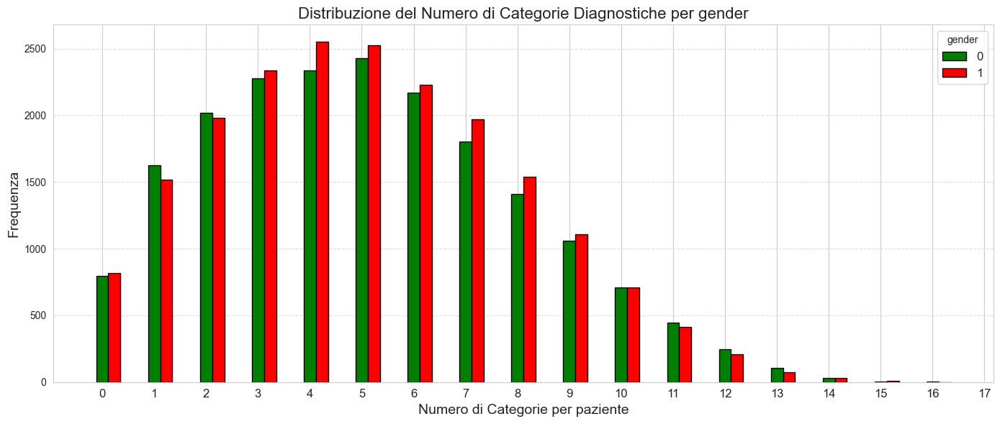

--------------------------
Classe: 0
num_categories
6     2429
5     2338
4     2275
7     2171
3     2017
8     1804
2     1625
9     1409
10    1057
1      794
11     710
12     448
13     244
14     107
15      31
16       5
17       2
Name: count, dtype: int64
--------------------------
Classe: 1
num_categories
5     2551
6     2523
4     2335
7     2228
3     1982
8     1971
9     1539
2     1516
10    1108
1      817
11     707
12     414
13     207
14      76
15      29
16       7
17       1
Name: count, dtype: int64


In [9]:
#-----------------------------------------
map_colors = {
    'normale': 'green',
    'ipertensione': 'red',
    'ipotensione': 'orange'
}
attr = "mean_arterial_pressure_class_max"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
attr = "mean_arterial_pressure_class_mean"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
attr = "mean_arterial_pressure_class_min"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
#--------------------------------------
map_colors = {
    'Normale': 'green',
    'Alto': 'red',
    'Basso': 'orange'
}
attr = "RR_HR_ratio_class_max"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
attr = "RR_HR_ratio_class_mean"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
attr = "RR_HR_ratio_class_min"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
#--------------------------------------
map_colors = {
    'normale': 'green',
    'critico': 'red',
    'basso': 'orange'
}
attr = "o2sat_class_min"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)

#--------------------------------------
map_colors = {
    'normale': 'green',
    'febbre': 'red',
    'ipotermia': 'orange'
}
attr = "temperature_class_max"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
attr = "temperature_class_min"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
attr = "temperature_class_mean"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
#---------------GIA VISTO IN PATIENTS PREPA---------------------
map_colors = {
    0: 'green',#vivo
    1: 'red',#morto
}
attr = "dod"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)

#------------------------------------
map_colors = {
    0: 'green', #maschio 'M': 0, 'F': 1
    1: 'red',#femmina
}
attr = "gender"
num_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['num_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)


In [6]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
       'o2sat_mean', 'mean_arterial_pressure_min',
       'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
       'temperature_class_mean', 'temperature_class_min',
       'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
       'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min',
       'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_mean',
       'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class'],
      dtype='object')

In [12]:
# Usa eval per convertire le stringhe in liste Python
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(lambda x: eval(x) if isinstance(x, str) else x)

In [16]:
young_deceased = patients_df[(patients_df['age_range_class'] == '0-30')]

In [25]:
def diagnosis_categories(map_colors, attr, title):

    # Estrai tutte le diagnosi uniche dalle categorie
    all_diagnoses = icd10_category['Code_range']
    all_diagnoses = sorted(all_diagnoses)  # Ordine alfabetico per coerenza

    map_groups = patients_df.groupby(attr)


    # Impostazioni grafiche
    plt.figure(figsize=(14, 6))
    bar_width = 0.22  # Larghezza di ogni barra
    space_between_categories = 0.5  # Spazio tra gruppi di categorie
    base_positions = np.arange(len(all_diagnoses)) * (bar_width * len(map_groups) + space_between_categories)

    # Aggiungi barre per ciascun gruppo di pressione arteriosa media
    for i, (map_class, group) in enumerate(map_groups):
        # Conta le occorrenze delle diagnosi per la classe di pressione
        diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
        diagnosis_counts = diagnosis_counts.reindex(all_diagnoses, fill_value=0)  # Assicurati che tutte le diagnosi siano rappresentate

        # Calcola le posizioni delle barre
        positions = base_positions + i * bar_width
        color = map_colors.get(map_class, 'gray')

        # Disegna le barre
        plt.bar(positions, diagnosis_counts.values, width=bar_width,
                label=f"{map_class}", color=color, edgecolor='black')

    # Configurazione del grafico
    plt.title(f"Distribuzione delle Diagnosi per Classi di {title}", fontsize=16)
    plt.xlabel("Categorie Diagnostiche (ICD-10)", fontsize=14)
    plt.ylabel("Frequenza", fontsize=14)
    plt.xticks(base_positions, all_diagnoses, rotation=45, ha='right', fontsize=10)
    plt.legend(fontsize=12, title=title)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

In [26]:
def diagnosis_categories_young(map_colors, attr, title):

    young_deceased = patients_df[(patients_df['age_range_class'] == '0-30')]

    # Estrai tutte le diagnosi uniche dalle categorie
    all_diagnoses = icd10_category['Code_range']
    all_diagnoses = sorted(all_diagnoses)  # Ordine alfabetico per coerenza

    map_groups = young_deceased.groupby(attr)


    # Impostazioni grafiche
    plt.figure(figsize=(14, 6))
    bar_width = 0.22  # Larghezza di ogni barra
    space_between_categories = 0.5  # Spazio tra gruppi di categorie
    base_positions = np.arange(len(all_diagnoses)) * (bar_width * len(map_groups) + space_between_categories)

    # Aggiungi barre per ciascun gruppo di pressione arteriosa media
    for i, (map_class, group) in enumerate(map_groups):
        # Conta le occorrenze delle diagnosi per la classe di pressione
        diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
        diagnosis_counts = diagnosis_counts.reindex(all_diagnoses, fill_value=0)  # Assicurati che tutte le diagnosi siano rappresentate

        # Calcola le posizioni delle barre
        positions = base_positions + i * bar_width
        color = map_colors.get(map_class, 'gray')

        # Disegna le barre
        plt.bar(positions, diagnosis_counts.values, width=bar_width,
                label=f"{map_class}", color=color, edgecolor='black')

    # Configurazione del grafico
    plt.title(f"Distribuzione delle Diagnosi per Classi di {title}", fontsize=16)
    plt.xlabel("Categorie Diagnostiche (ICD-10)", fontsize=14)
    plt.ylabel("Frequenza", fontsize=14)
    plt.xticks(base_positions, all_diagnoses, rotation=45, ha='right', fontsize=10)
    plt.legend(fontsize=12, title=title)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

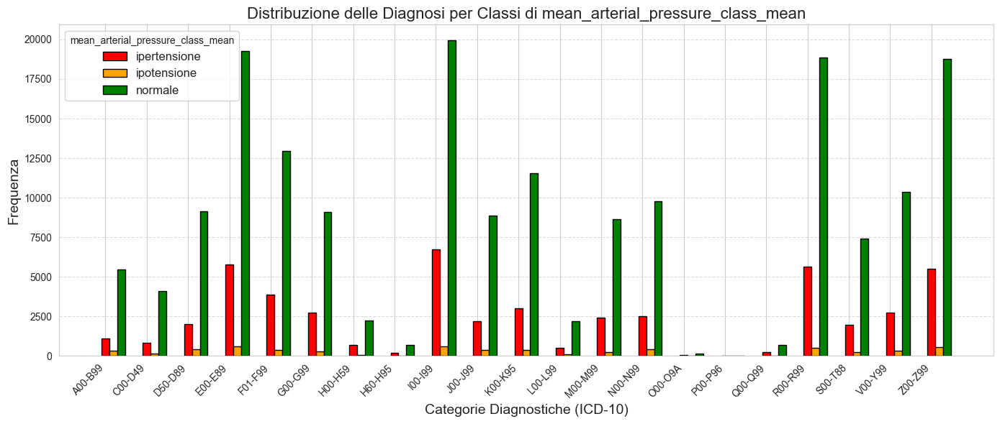

--------------------------
Classe: ipertensione
diagnosis_categories
I00-I99    6758
E00-E89    5781
R00-R99    5654
Z00-Z99    5531
F01-F99    3870
K00-K95    3002
V00-Y99    2754
G00-G99    2752
N00-N99    2534
M00-M99    2422
J00-J99    2181
D50-D89    2025
S00-T88    1960
A00-B99    1114
C00-D49     833
H00-H59     710
L00-L99     522
Q00-Q99     242
H60-H95     195
O00-O9A      52
P00-P96       3
Name: count, dtype: int64
--------------------------
Classe: ipotensione
diagnosis_categories
I00-I99    597
E00-E89    592
Z00-Z99    579
R00-R99    527
N00-N99    432
D50-D89    419
K00-K95    400
J00-J99    364
F01-F99    359
V00-Y99    326
A00-B99    318
G00-G99    271
S00-T88    235
M00-M99    233
C00-D49    135
L00-L99    116
H00-H59     59
Q00-Q99     26
H60-H95     20
O00-O9A      4
Name: count, dtype: int64
--------------------------
Classe: normale
diagnosis_categories
I00-I99    19932
E00-E89    19266
R00-R99    18865
Z00-Z99    18791
F01-F99    12969
K00-K95    11567
V00-Y99  

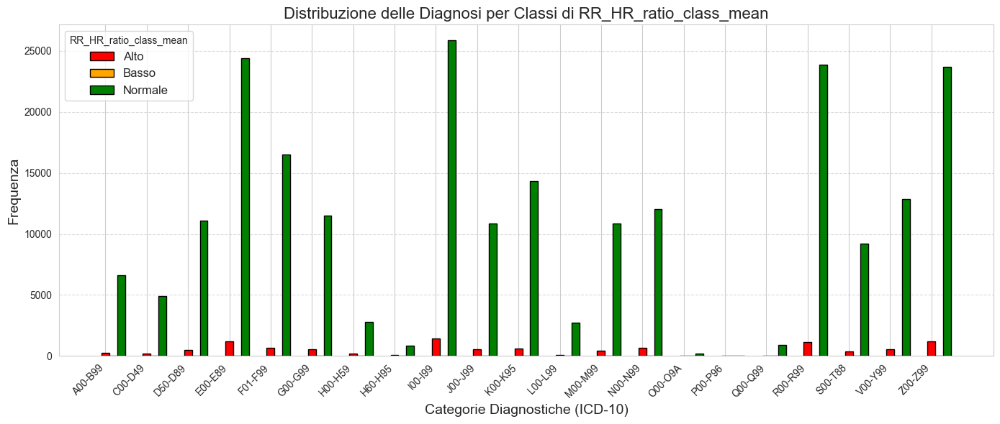

--------------------------
Classe: Alto
diagnosis_categories
I00-I99    1407
E00-E89    1221
Z00-Z99    1194
R00-R99    1153
N00-N99     660
F01-F99     648
K00-K95     614
V00-Y99     576
G00-G99     571
J00-J99     544
D50-D89     500
M00-M99     446
S00-T88     374
A00-B99     277
C00-D49     189
H00-H59     173
L00-L99     100
H60-H95      61
Q00-Q99      43
O00-O9A      12
Name: count, dtype: int64
--------------------------
Classe: Basso
diagnosis_categories
I00-I99    34
Z00-Z99    32
R00-R99    30
E00-E89    28
F01-F99    25
V00-Y99    22
J00-J99    19
K00-K95    19
D50-D89    17
S00-T88    17
N00-N99    14
M00-M99    14
G00-G99    14
A00-B99    11
L00-L99     4
C00-D49     3
H00-H59     2
Name: count, dtype: int64
--------------------------
Classe: Normale
diagnosis_categories
I00-I99    25846
E00-E89    24390
R00-R99    23863
Z00-Z99    23675
F01-F99    16525
K00-K95    14336
V00-Y99    12843
N00-N99    12048
G00-G99    11513
D50-D89    11078
J00-J99    10855
M00-M99    10826

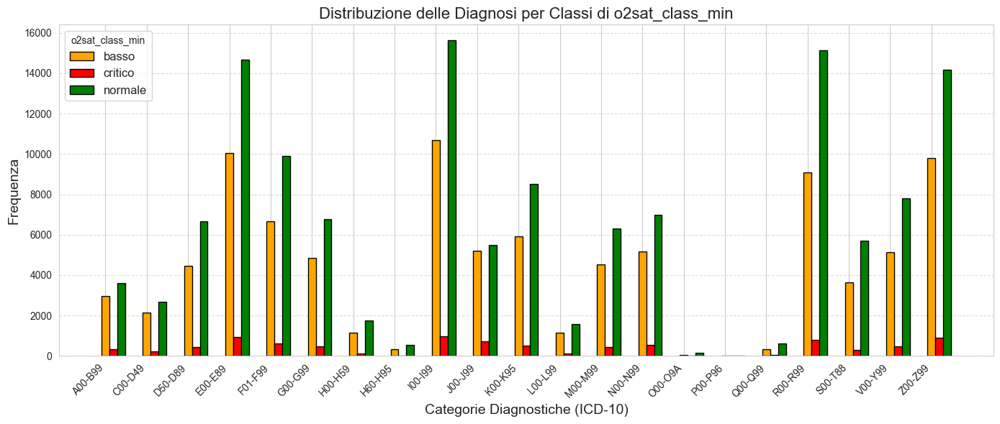

--------------------------
Classe: basso
diagnosis_categories
I00-I99    10690
E00-E89    10056
Z00-Z99     9804
R00-R99     9098
F01-F99     6672
K00-K95     5924
J00-J99     5215
N00-N99     5159
V00-Y99     5133
G00-G99     4864
M00-M99     4544
D50-D89     4463
S00-T88     3629
A00-B99     2961
C00-D49     2140
L00-L99     1148
H00-H59     1139
H60-H95      350
Q00-Q99      321
O00-O9A       41
P00-P96        1
Name: count, dtype: int64
--------------------------
Classe: critico
diagnosis_categories
I00-I99    975
E00-E89    924
Z00-Z99    908
R00-R99    812
J00-J99    720
F01-F99    617
N00-N99    560
K00-K95    529
V00-Y99    484
G00-G99    467
D50-D89    454
M00-M99    430
A00-B99    330
S00-T88    284
C00-D49    242
L00-L99    124
H00-H59    109
Q00-Q99     40
H60-H95     27
O00-O9A      1
Name: count, dtype: int64
--------------------------
Classe: normale
diagnosis_categories
I00-I99    15622
R00-R99    15136
E00-E89    14659
Z00-Z99    14189
F01-F99     9909
K00-K95     8516

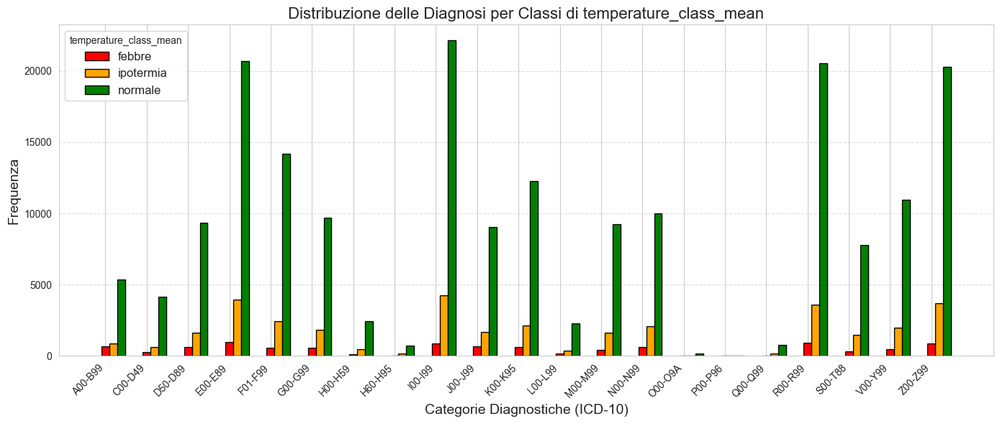

--------------------------
Classe: febbre
diagnosis_categories
E00-E89    953
R00-R99    921
I00-I99    882
Z00-Z99    878
J00-J99    689
A00-B99    677
N00-N99    629
D50-D89    617
K00-K95    603
F01-F99    584
G00-G99    551
V00-Y99    471
M00-M99    416
S00-T88    328
C00-D49    248
L00-L99    185
H00-H59    108
Q00-Q99     43
H60-H95     29
O00-O9A      9
P00-P96      1
Name: count, dtype: int64
--------------------------
Classe: ipotermia
diagnosis_categories
I00-I99    4265
E00-E89    3967
Z00-Z99    3724
R00-R99    3577
F01-F99    2429
K00-K95    2114
N00-N99    2091
V00-Y99    1999
G00-G99    1831
J00-J99    1669
M00-M99    1614
D50-D89    1610
S00-T88    1497
A00-B99     879
C00-D49     649
H00-H59     462
L00-L99     386
H60-H95     149
Q00-Q99     145
O00-O9A      15
Name: count, dtype: int64
--------------------------
Classe: normale
diagnosis_categories
I00-I99    22140
E00-E89    20719
R00-R99    20548
Z00-Z99    20299
F01-F99    14185
K00-K95    12252
V00-Y99    10971
N

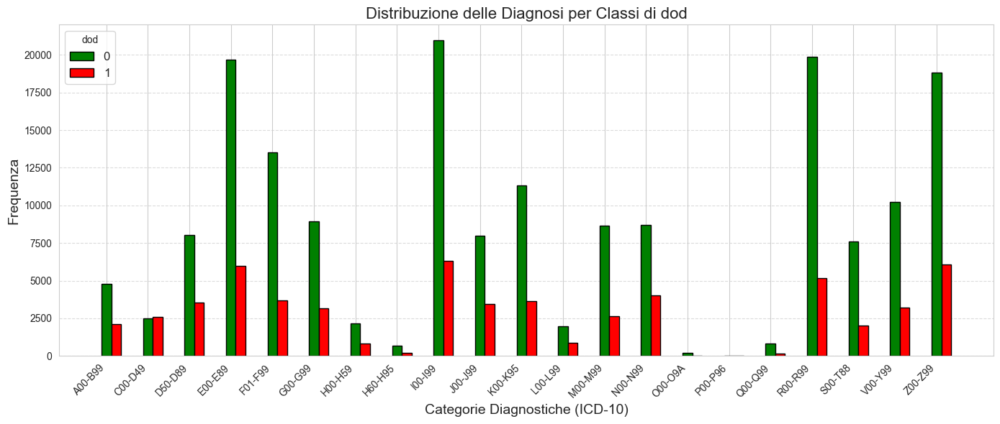

--------------------------
Classe: 0
diagnosis_categories
I00-I99    20953
R00-R99    19875
E00-E89    19664
Z00-Z99    18820
F01-F99    13506
K00-K95    11339
V00-Y99    10216
G00-G99     8935
N00-N99     8688
M00-M99     8663
D50-D89     8046
J00-J99     7966
S00-T88     7586
A00-B99     4790
C00-D49     2478
H00-H59     2173
L00-L99     1986
Q00-Q99      816
H60-H95      706
O00-O9A      207
P00-P96        4
Name: count, dtype: int64
--------------------------
Classe: 1
diagnosis_categories
I00-I99    6334
Z00-Z99    6081
E00-E89    5975
R00-R99    5171
N00-N99    4034
F01-F99    3692
K00-K95    3630
D50-D89    3549
J00-J99    3452
V00-Y99    3225
G00-G99    3163
M00-M99    2623
C00-D49    2597
A00-B99    2120
S00-T88    2038
L00-L99     866
H00-H59     816
H60-H95     220
Q00-Q99     155
O00-O9A       3
Name: count, dtype: int64


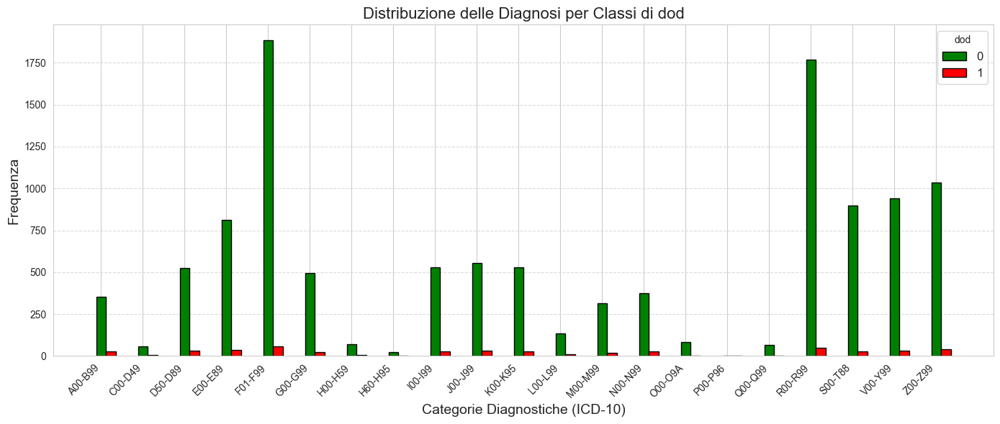

--------------------------
Classe: 0
diagnosis_categories
F01-F99    1883
R00-R99    1767
Z00-Z99    1037
V00-Y99     942
S00-T88     897
E00-E89     813
J00-J99     553
K00-K95     530
I00-I99     530
D50-D89     524
G00-G99     495
N00-N99     375
A00-B99     352
M00-M99     316
L00-L99     134
O00-O9A      83
H00-H59      72
Q00-Q99      64
C00-D49      56
H60-H95      21
P00-P96       1
Name: count, dtype: int64
--------------------------
Classe: 1
diagnosis_categories
F01-F99    56
R00-R99    50
Z00-Z99    40
E00-E89    36
V00-Y99    33
D50-D89    33
J00-J99    30
S00-T88    29
A00-B99    29
I00-I99    29
K00-K95    26
N00-N99    26
G00-G99    23
M00-M99    18
L00-L99     9
H00-H59     6
C00-D49     6
H60-H95     3
O00-O9A     2
Q00-Q99     2
Name: count, dtype: int64


In [27]:
#-----------------------------------------
map_colors = {
    'normale': 'green',
    'ipertensione': 'red',
    'ipotensione': 'orange'
}
attr = "mean_arterial_pressure_class_mean"
diagnosis_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)

# #--------------------------------------
map_colors = {
    'Normale': 'green',
    'Alto': 'red',
    'Basso': 'orange'
}
attr = "RR_HR_ratio_class_mean"
diagnosis_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)

# #--------------------------------------
map_colors = {
    'normale': 'green',
    'critico': 'red',
    'basso': 'orange'
}
attr = "o2sat_class_min"
diagnosis_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)

# #--------------------------------------
map_colors = {
    'normale': 'green',
    'febbre': 'red',
    'ipotermia': 'orange'
}
attr = "temperature_class_mean"
diagnosis_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)

#------------------------------------
map_colors = {
    0: 'green',#vivo
    1: 'red',#morto
}
attr = "dod"
diagnosis_categories(map_colors, attr, attr)
map_groups = patients_df.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
# ----------------YOUNG----------------
map_colors = {
    0: 'green',#vivo
    1: 'red',#morto
}
attr = "dod"
diagnosis_categories_young(map_colors, attr, attr)
map_groups = young_deceased.groupby(attr)
for map_class, group in map_groups:
    diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
    print(f"--------------------------\nClasse: {map_class}")
    print(diagnosis_counts)
#------------------------------------
# map_colors = {
#     0: 'green', #uomini
#     1: 'red',#donne
# }
# attr = "gender"
# diagnosis_categories(map_colors, attr, attr)
# map_groups = young_deceased.groupby(attr)
# for map_class, group in map_groups:
#     diagnosis_counts = group['diagnosis_categories'].explode().value_counts()
#     print(f"--------------------------\nClasse: {map_class}")
#     print(diagnosis_counts)


In [18]:
icd10_category

,Code_range,Description
0,A00-B99,Certain infectious and parasitic diseases
1,C00-D49,Neoplasms
2,D50-D89,Diseases of the blood and blood-forming organs...
3,E00-E89,"Endocrine, nutritional and metabolic diseases"
4,F01-F99,"Mental, Behavioral and Neurodevelopmental diso..."
5,G00-G99,Diseases of the nervous system
6,H00-H59,Diseases of the eye and adnexa
7,H60-H95,Diseases of the ear and mastoid process
8,I00-I99,Diseases of the circulatory system
9,J00-J99,Diseases of the respiratory system


F01-F99    56
R00-R99    50
Z00-Z99    40

In [32]:

f= ['gender', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'o2sat_min', 'o2sat_max',
       'mean_arterial_pressure_min', 'mean_arterial_pressure_max',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'temperature_mean', 'o2sat_mean',
       'heartrate_mean', 'resprate_mean', 'sbp_mean', 'dbp_mean', 'temperature_class',
       'o2sat_class', 'mean_arterial_pressure', 'mean_arterial_pressure_class',
       'RR_HR_ratio', 'RR_HR_ratio_class', 'age_range_class']

In [169]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
       'o2sat_mean', 'mean_arterial_pressure_min',
       'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
       'temperature_class_mean', 'temperature_class_min',
       'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
       'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min',
       'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_mean',
       'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class'],
      dtype='object')

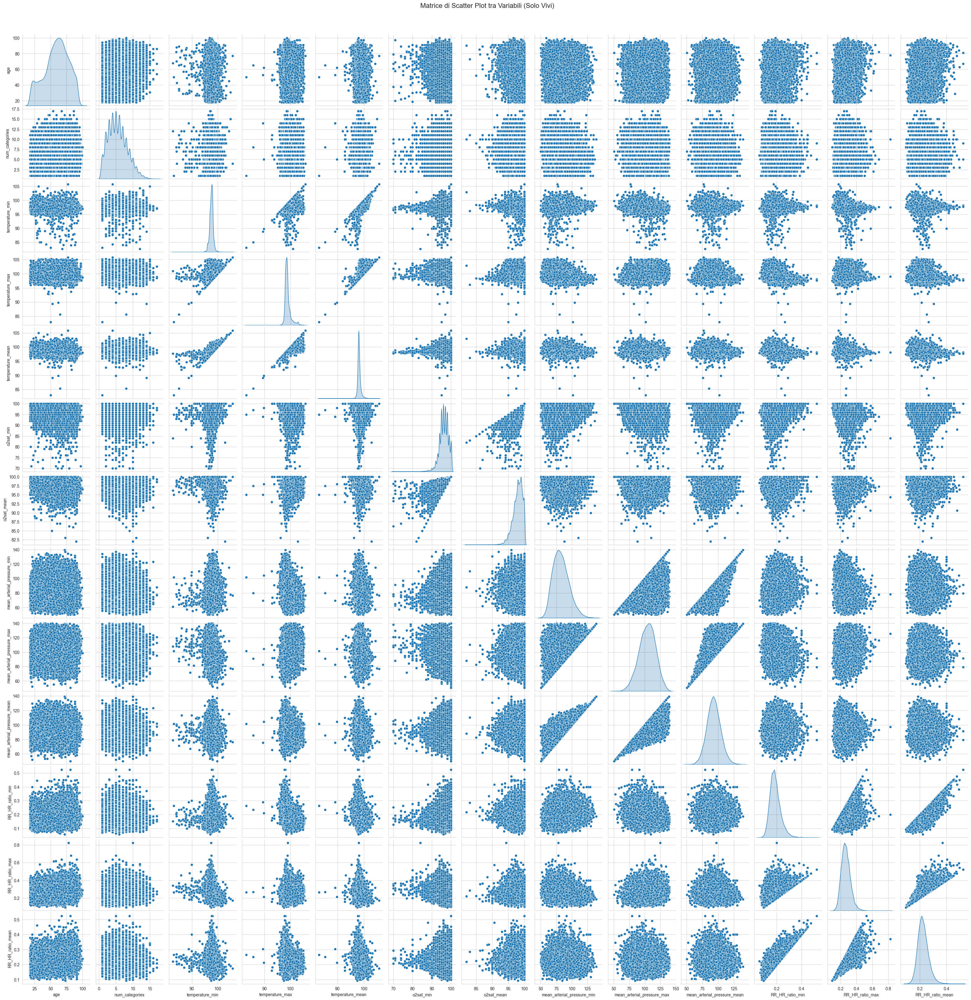

In [201]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filtra i pazienti vivi (dod == 0)
patients_alive = patients_df[patients_df['dod'] == 0]

# Seleziona le feature da includere nella matrice di scatter plot
selected_features = [
    'age', 'num_categories', 'temperature_min', 'temperature_max', 'temperature_mean',
    'o2sat_min', 'o2sat_mean', 'mean_arterial_pressure_min', 'mean_arterial_pressure_max',
    'mean_arterial_pressure_mean', 'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean'
]

# Crea una matrice di scatter plot
sns.pairplot(patients_alive[selected_features], diag_kind='kde', height=2.5)

# Imposta il titolo
plt.suptitle('Matrice di Scatter Plot tra Variabili (Solo Vivi)', y=1.02, fontsize=16)
plt.show()


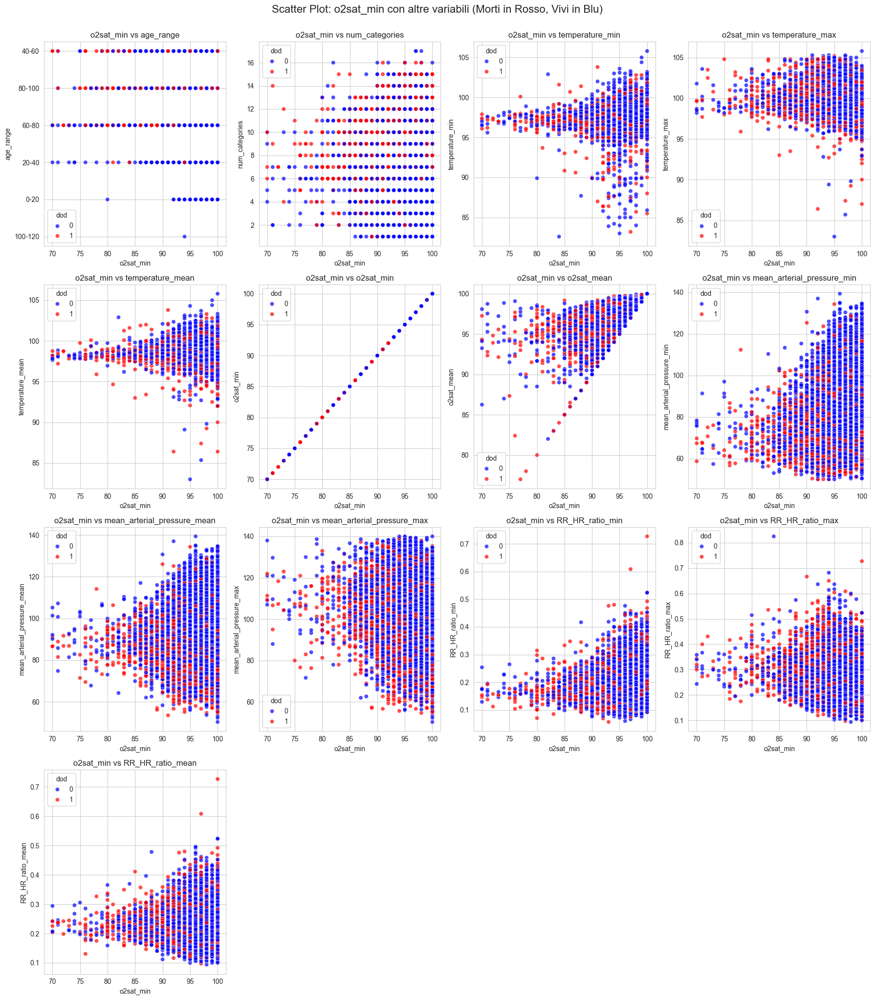

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Lista delle feature selezionate
selected_features = [
    'age_range', 'num_categories', 'temperature_min', 'temperature_max', 'temperature_mean',
    'o2sat_min', 'o2sat_mean', 'mean_arterial_pressure_min', 'mean_arterial_pressure_mean',
    'mean_arterial_pressure_max', 'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean'
]

# Funzione per generare scatter plot con 4 grafici per riga e distinzione per morti/vivi
def scatter_plots_row(feature, other_features, df, n_cols=4):
    n_rows = -(-len(other_features) // n_cols)  # Calcola il numero di righe necessarie
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, other_feature in enumerate(other_features):
        row, col = divmod(idx, n_cols)
        ax = axes[row, col] if n_rows > 1 else axes[col]  # Compatibile con 1 riga
        sns.scatterplot(
            data=df,
            x=feature,
            y=other_feature,
            hue='dod',  # Colore basato su "dod" (vivi e morti)
            palette={0: 'blue', 1: 'red'},  # Blu per vivi, rosso per morti
            ax=ax,
            alpha=0.7
        )
        ax.set_title(f'{feature} vs {other_feature}', fontsize=12)
        ax.set_xlabel(feature)
        ax.set_ylabel(other_feature)

    # Rimuovi assi vuoti
    for idx in range(len(other_features), n_rows * n_cols):
        fig.delaxes(axes.flat[idx])

    plt.tight_layout()
    plt.suptitle(f'Scatter Plot: {feature} con altre variabili (Morti in Rosso, Vivi in Blu)', y=1.02, fontsize=16)
    plt.show()

# Esegui la funzione per una feature rispetto alle altre
scatter_plots_row('o2sat_min', selected_features, patients_df)


In [174]:
import seaborn as sns
import matplotlib.pyplot as plt

# Lista delle feature selezionate
selected_features = [
    'age_range', 'num_categories', 'temperature_min', 'temperature_max',
    'o2sat_min', 'o2sat_max', 'mean_arterial_pressure_min',
    'mean_arterial_pressure_max', 'RR_HR_ratio_min', 'RR_HR_ratio_max',
    'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure', 'RR_HR_ratio'
]

# Funzione per generare scatter plot con 4 grafici per riga
def scatter_plots_row(feature, other_features, df, n_cols=4):
    n_rows = -(-len(other_features) // n_cols)  # Calcola il numero di righe necessarie
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, other_feature in enumerate(other_features):
        row, col = divmod(idx, n_cols)
        ax = axes[row, col] if n_rows > 1 else axes[col]  # Compatibile con 1 riga
        sns.scatterplot(data=df, x=feature, y=other_feature, ax=ax, alpha=0.7)
        ax.set_title(f'{feature} vs {other_feature}', fontsize=12)
        ax.set_xlabel(feature)
        ax.set_ylabel(other_feature)

    # Rimuovi assi vuoti
    for idx in range(len(other_features), n_rows * n_cols):
        fig.delaxes(axes.flat[idx])

    plt.tight_layout()
    plt.suptitle(f'Scatter Plot: {feature} con altre variabili', y=1.02, fontsize=16)
    plt.show()


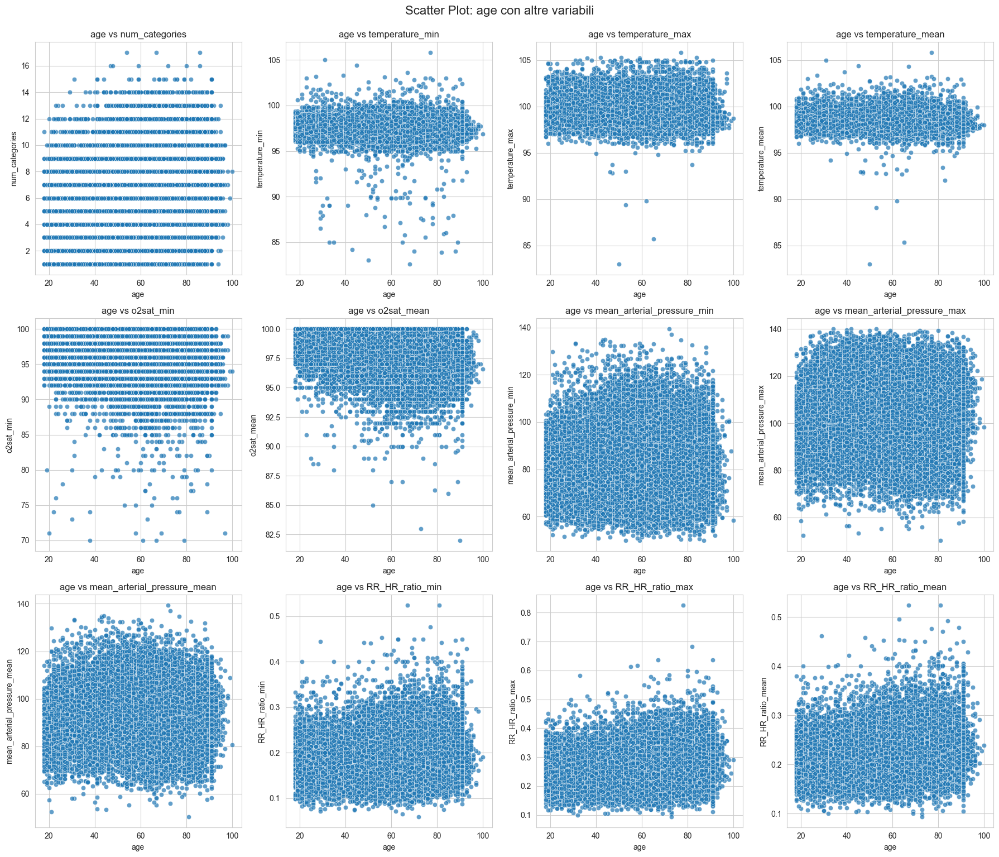

In [202]:
scatter_plots_row('age', ['num_categories',
                                'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
                                'o2sat_mean', 'mean_arterial_pressure_min',
                                'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
                                'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean'
], patients_alive)


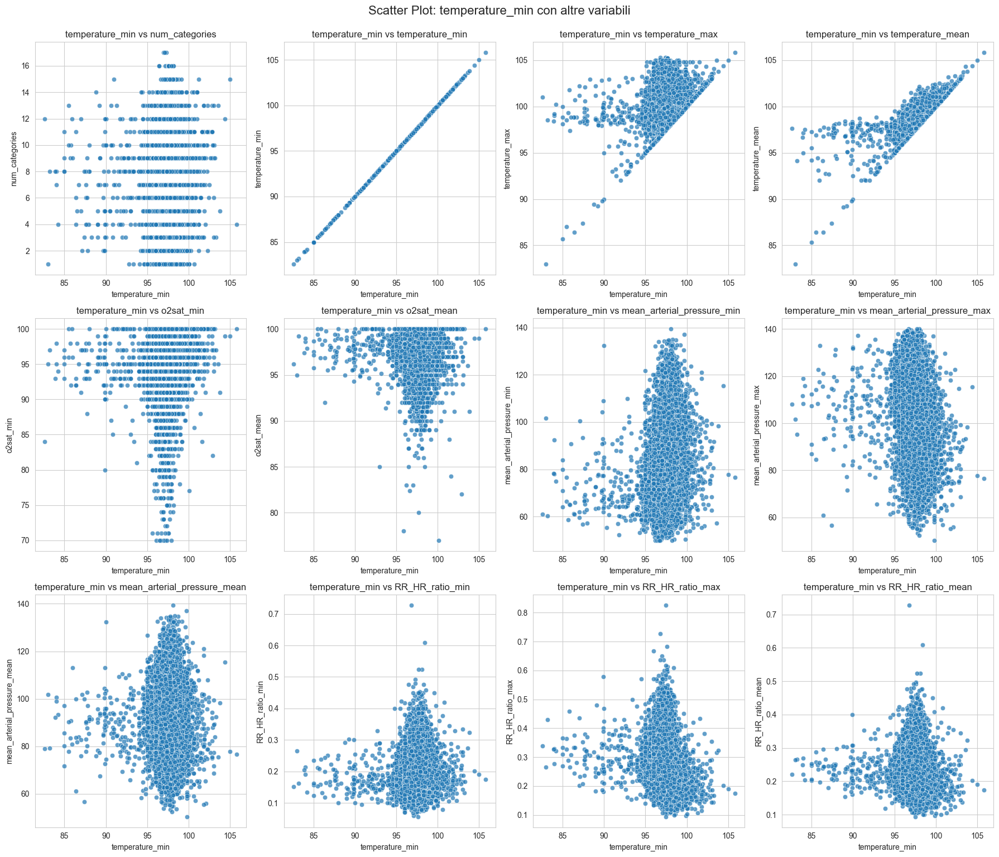

In [176]:
scatter_plots_row('temperature_min', ['num_categories',
                                      'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
                                      'o2sat_mean', 'mean_arterial_pressure_min',
                                      'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
                                      'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean'
], patients_df)


---
## **Scelta degli indicatori da usare dopo**

In [101]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_mean', 'o2sat_mean', 'temperature_status', 'o2sat_status',
       'mean_arterial_pressure', 'mean_arterial_pressure_status',
       'RR_HR_ratio', 'RR_HR_ratio_status'],
      dtype='object')

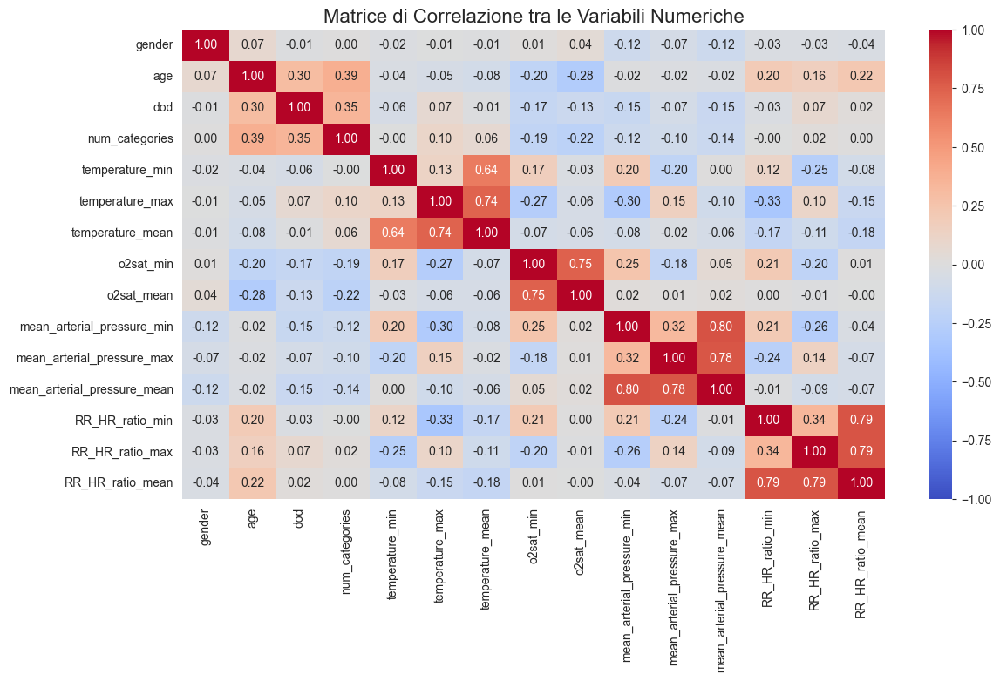

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Seleziona solo le colonne numeriche dalla lista
numerical_features = ['gender', 'age', 'dod', 'num_categories',
                      'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
                      'o2sat_mean', 'mean_arterial_pressure_min',
                      'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
                      'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
]

# Calcola la matrice di correlazione
correlation_matrix = patients_df[numerical_features].corr()

# Crea una heatmap della matrice di correlazione
plt.figure(figsize=(13, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matrice di Correlazione tra le Variabili Numeriche', fontsize=16)
plt.show()


In [115]:
# Eliminazione attributi con correlazione alta e mean gia presenti in attributi composti

In [93]:
features = ['age', 'dod', 'num_categories', 'temperature_mean', 'o2sat_min',
            'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']


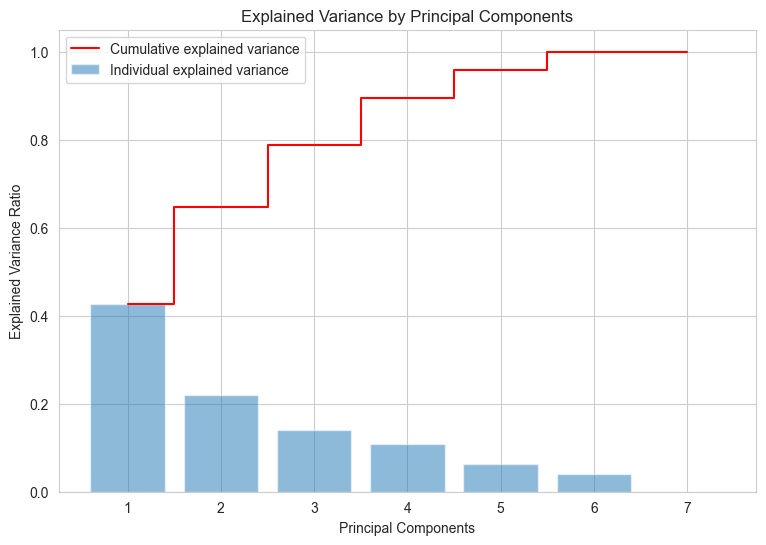

Most Important Leads for the First 3 Principal Components:
PC1: num_categories, dod, o2sat_min
PC2: temperature_mean, RR_HR_ratio_mean, age
PC3: mean_arterial_pressure_mean, o2sat_min, RR_HR_ratio_mean
PC4: RR_HR_ratio_mean, o2sat_min, temperature_mean
PC5: dod, num_categories, age


In [94]:
from sklearn.decomposition import PCA
features = ['age', 'dod', 'num_categories', 'temperature_mean', 'o2sat_min',
            'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']

## UTILE NEL CLUSTERING
scaler = StandardScaler()
normalized_patients_df = pd.DataFrame()
normalized_patients_df = scaler.fit_transform(patients_df[features])
normalized_patients_df = pd.DataFrame(normalized_patients_df, columns=features)  # Sostituisci i nomi delle colonne

# del range
# Load the correlation matrix
corr_matrix = normalized_patients_df.corr()

# Perform PCA using the correlation matrix
pca = PCA()
pca.fit(corr_matrix)

# Extract the explained variance ratios
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Plot the explained variance ratios to visualize how much variance each component explains
plt.figure(figsize=(9, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.5, align='center',
        label='Individual explained variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid',
         label='Cumulative explained variance', color='red')
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance by Principal Components')
plt.legend(loc='best')
plt.grid(True)
plt.show()

# Analyze PCA components
components_df = pd.DataFrame(pca.components_, columns=corr_matrix.columns)

# Identify the most important leads based on the absolute values of the loadings
most_important_leads = {}
num_components = 5  # Specify how many components to analyze PC1, PC", ...
num_components = min(num_components, components_df.shape[0])
for i in range(num_components):
    component = components_df.iloc[i]
    # Top 2 leads per component by setting head(2) and 3 putting head(3)
    top_leads = component.abs().sort_values(ascending=False).head(3).index.tolist()
    most_important_leads[f"PC{i + 1}"] = top_leads

print("Most Important Leads for the First 3 Principal Components:")
for pc, leads in most_important_leads.items():
    print(f"{pc}: {', '.join(leads)}")

# Save PCA components and explained variance for further analysis
components_df.to_csv("pca_components.csv", index=False)
pd.DataFrame(explained_variance, columns=["Explained Variance Ratio"]).to_csv("pca_explained_variance.csv", index=False)



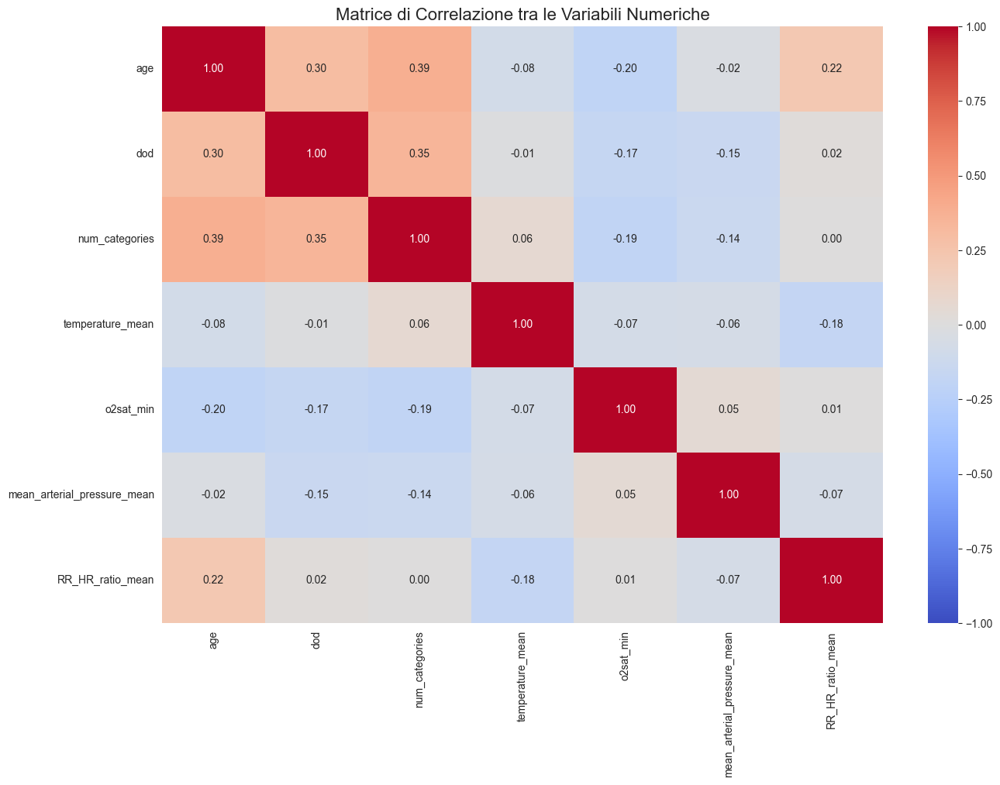

In [95]:

# Crea una heatmap della matrice di correlazione
plt.figure(figsize=(15, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matrice di Correlazione tra le Variabili Numeriche', fontsize=16)
plt.show()

In [1]:
from itertools import combinations

# Lista completa delle feature numeriche
numerical_features = ['age', 'num_categories', 'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
    'o2sat_mean', 'mean_arterial_pressure_min', 'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
    'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']

# Gruppi di feature correlate
feature_groups = [
    ['temperature_min', 'temperature_max', 'temperature_mean'],  # Temperature
    ['o2sat_min', 'o2sat_mean'],                                # O2 Saturation
    ['mean_arterial_pressure_min', 'mean_arterial_pressure_max', 'mean_arterial_pressure_mean'],  # Arterial Pressure
    ['RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']  # RR_HR Ratio
]

# Funzione per filtrare le combinazioni
def filter_combinations(features, groups, min_len, max_len):
    valid_combinations = []
    for r in range(min_len, max_len + 1):
        for combo in combinations(features, r):
            # Verifica che non ci siano più di un elemento per ogni gruppo
            if all(sum(1 for f in combo if f in group) <= 1 for group in groups):
                valid_combinations.append(list(combo))
    return valid_combinations

# Ottieni le combinazioni filtrate
filtered_combinations = filter_combinations(numerical_features, feature_groups, 5, 6)

print(f"Generated {len(filtered_combinations)} valid combinations.")

Generated 243 valid combinations.


In [3]:
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler

patients_df = pd.read_csv('../datasets/general_patients_TAB.csv')


# Combinazioni di normalizzazione da applicare
normalization_methods = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler()
}

# Inizializza una lista per memorizzare i risultati
results = []

# Itera su ogni metodo di normalizzazione
for norm_name, scaler in normalization_methods.items():
    # Itera su tutte le combinazioni di features
    for i, features in enumerate(filtered_combinations):
        normalized_patients_df = pd.DataFrame(scaler.fit_transform(patients_df[features]), columns=features)
        print(f'{i} | features: {features} | Normalization: {norm_name}')

        # Prova con un numero di cluster da 2 a 3
        for n_clusters in range(2, 4):
            kmeans = KMeans(n_clusters=n_clusters, random_state=42)
            kmeans.fit(normalized_patients_df)

            # Calcola le metriche
            silhouette_all = silhouette_score(normalized_patients_df, kmeans.labels_)
            kmeans_db = davies_bouldin_score(normalized_patients_df, kmeans.labels_)

            # Calcola la distribuzione dei dati nei cluster
            cluster_counts = pd.Series(kmeans.labels_).value_counts().to_dict()

            # print(f"Number of clusters: {n_clusters} | Silhouette Score: {silhouette_all:.3f} | Davies-Bouldin Index: {kmeans_db:.3f}")

            # Aggiungi i risultati alla lista
            results.append({
                "Normalization": norm_name,
                "Silhouette": silhouette_all,
                "Davies_Bouldin": kmeans_db,
                "Clusters": n_clusters,
                "Cluster_Distribution": cluster_counts,
                "Features": features
            })
            
# 4h 19min

0 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_min', 'mean_arterial_pressure_min'] | Normalization: StandardScaler
1 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_min', 'mean_arterial_pressure_max'] | Normalization: StandardScaler
2 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_min', 'mean_arterial_pressure_mean'] | Normalization: StandardScaler
3 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_min', 'RR_HR_ratio_min'] | Normalization: StandardScaler
4 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_min', 'RR_HR_ratio_max'] | Normalization: StandardScaler
5 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_min', 'RR_HR_ratio_mean'] | Normalization: StandardScaler
6 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_mean', 'mean_arterial_pressure_min'] | Normalization: StandardScaler
7 | features: ['age', 'num_categories', 'temperature_min', 'o2sat_mean', 'mean_arterial_pres

In [4]:

# Converti i risultati in un DataFrame
results_df = pd.DataFrame(results)

# Salva il DataFrame in un file CSV
results_df.to_csv("../datasets/list_Silouhette_Davies_Bouldin_TAB.csv", index=False)

print("Risultati salvati in '../datasets/list_Silouhette_Davies_Bouldin_TAB.csv'")


Risultati salvati in '../datasets/list_Silouhette_Davies_Bouldin_TAB.csv'


In [5]:
len(results_df)

972